# Crowdcast: best time to travel by Namma Metro (Bengaluru)

**Goal:** for any Namma Metro station and day of the week, predict how crowded each hour will be, and
recommend the least crowded time to travel.

**Data:** BMRCL station-wise hourly ridership, released through an RTI request (credit: Vivek Mathew) and
published on [OpenCity](https://data.opencity.in/dataset/bmrcl-station-wise-ridership-data)
(Creative Commons Non-Commercial). Two files:
- 1–18 Aug 2025: hourly ridership per station
- 1–30 Sep 2025: hourly **entries** and exits per station

We checked before building anything that August's "ridership" means **station entries**: its hourly
pattern matches September's entries with correlation 0.997, and does not match exits. So the target
throughout is **people entering the station per hour**, which is a direct measure of how crowded
boarding is.

**Plan:**
1. Load, reshape and explore.
2. Split by time: train on 1 Aug–21 Sep, test on **22–30 Sep**, which is never seen during training.
3. Compare three models:
   - *same hour last week* (baseline)
   - *average weekly pattern*
   - **XGBoost**
4. Save the best model's weekly pattern for every station, for the app.

## 1. Setup

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
print("pandas", pd.__version__, "| xgboost", xgb.__version__)

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
DATA = os.path.join(ROOT, "data", "bmrcl")
APP_DATA = os.path.join(ROOT, "app", "data")
os.makedirs(APP_DATA, exist_ok=True)

TEST_START = pd.Timestamp("2025-09-22")     # test week: 22-30 Sep 2025
OPEN_HOURS = range(6, 23)                   # hours we recommend from: 6 am to 11 pm
HOLIDAYS = {pd.Timestamp("2025-08-15"): "Independence Day"}
SEED = 42

pandas 3.1.1 | xgboost 3.4.1


## 2. Load and reshape

Each file has one row per station per day, with 24 hourly columns. We turn this into one row per
**station, date, hour**. Stations are matched by their numeric code, since station 111 was renamed
from "Bangalore City Station" (August) to "KSR Railway Station" (September).

In [2]:
def load(path, sheet=0):
    df = pd.read_excel(path, sheet_name=sheet)
    hour_cols = df.columns[2:26]
    df = df.rename(columns={df.columns[0]: "date", df.columns[1]: "station_raw"})
    df = df.rename(columns={c: h for h, c in enumerate(hour_cols)})
    long = df.melt(id_vars=["date", "station_raw"], value_vars=list(range(24)), var_name="hour", value_name="entries")
    long["date"] = pd.to_datetime(long["date"])
    long["hour"] = long["hour"].astype(int)
    long["entries"] = pd.to_numeric(long["entries"], errors="coerce")
    long["code"] = long["station_raw"].str.split("-", n=1).str[0].astype(int)
    long["name"] = long["station_raw"].str.split("-", n=1).str[1].str.strip()
    return long

aug = load(os.path.join(DATA, "aug2025_station_hourly.xlsx"))
sep = load(os.path.join(DATA, "sep2025_station_hourly_entry_exit.xlsx"), sheet="Sep-2025 Entry")
df = pd.concat([aug, sep], ignore_index=True)

# One name per station code: the most recent one (September).
latest_name = df.sort_values("date").groupby("code")["name"].last()
df["station"] = df["code"].map(latest_name)
df = df.drop(columns=["station_raw", "name"])

print(f"{len(df):,} rows | {df['station'].nunique()} stations | {df['date'].min():%d %b} to {df['date'].max():%d %b %Y}"
      f" | {df['date'].nunique()} days | missing values: {df['entries'].isna().sum()}")
first_day = df[df["entries"] > 0].groupby("station")["date"].min()
late = first_day[first_day > df["date"].min()].sort_values()
print(f"\n{len(late)} stations have no data at the start of August (opened later):")
print(late.dt.strftime("%d %b %Y").value_counts().sort_index().to_string())

92,280 rows | 83 stations | 01 Aug to 30 Sep 2025 | 48 days | missing values: 0

15 stations have no data at the start of August (opened later):
date
03 Aug 2025    1
06 Aug 2025    2
07 Aug 2025    1
08 Aug 2025    1
09 Aug 2025    1
11 Aug 2025    9


## 3. Explore

How much does ridership change by day, and what does a typical day look like?

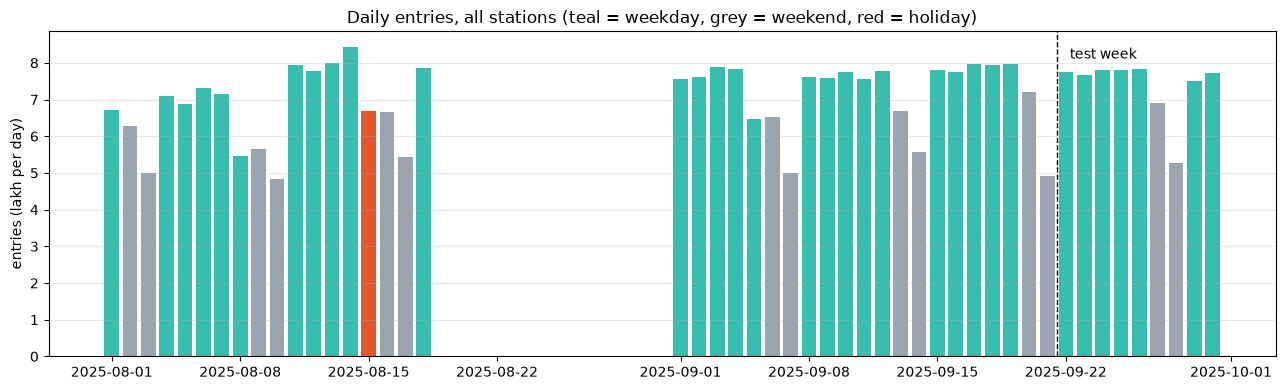

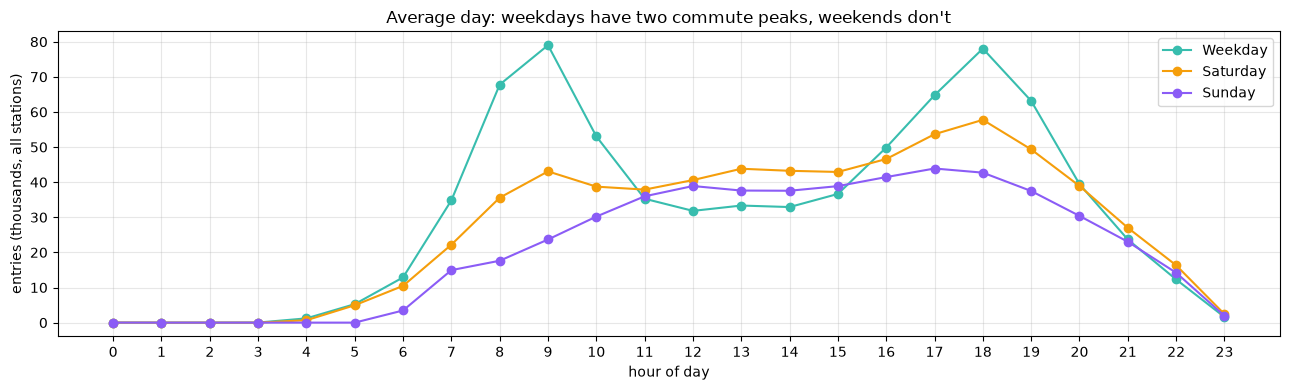

Busiest stations (average entries per day):
station
Kempegowda                    34365
Benniganahalli                26055
Indiranagar                   21853
MG Road                       20983
Krishnarajapura               18844
Mantri Square Sampige Road    16594
Chickpete                     15372
Cubbon Park                   13880
Yeshwanthpur                  13879
Baiyappanahalli               13430


In [3]:
daily = df.groupby("date")["entries"].sum()
fig, ax = plt.subplots(figsize=(13, 4))
colors = ["#e4572e" if d in HOLIDAYS else ("#9aa5b1" if d.day_of_week >= 5 else "#38bdae") for d in daily.index]
ax.bar(daily.index, daily.values / 1e5, color=colors)
ax.axvline(TEST_START - pd.Timedelta(hours=12), ls="--", c="k", lw=1)
ax.text(TEST_START, ax.get_ylim()[1] * 0.95, " test week", va="top")
ax.set(ylabel="entries (lakh per day)", title="Daily entries, all stations (teal = weekday, grey = weekend, red = holiday)")
ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

d = df.assign(kind=np.select([df.date.dt.day_of_week < 5, df.date.dt.day_of_week == 5], ["Weekday", "Saturday"], "Sunday"))
d = d[~d["date"].isin(HOLIDAYS)]
prof = d.groupby(["kind", "date", "hour"])["entries"].sum().groupby(["kind", "hour"]).mean().unstack(0) / 1000
fig, ax = plt.subplots(figsize=(13, 4))
for k, c in [("Weekday", "#38bdae"), ("Saturday", "#f59e0b"), ("Sunday", "#8b5cf6")]:
    ax.plot(prof.index, prof[k], "o-", c=c, label=k)
ax.set(xlabel="hour of day", ylabel="entries (thousands, all stations)", title="Average day: weekdays have two commute peaks, weekends don't",
       xticks=range(0, 24))
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

top = df.groupby("station")["entries"].sum().div(df["date"].nunique()).sort_values(ascending=False).head(10)
print("Busiest stations (average entries per day):")
print(top.round(0).astype(int).to_string())

## 4. Train / test split and features

The split is **by time**: the model only sees data up to 21 Sep and is tested on 22–30 Sep, just
like predicting a future week. Features are:
- station
- day of week
- hour
- weekend flag
- holiday flag

The models learn each station's **typical** pattern, which is what the app needs ("what is Tuesday
8 am usually like at MG Road?"), rather than depending on last week's exact numbers.

In [4]:
df["weekday"] = df["date"].dt.day_of_week
df["weekend"] = (df["weekday"] >= 5).astype(int)
df["holiday"] = df["date"].isin(HOLIDAYS).astype(int)

# Drop station-days before each station opened (all zeros), so they don't look like "quiet" days.
day_total = df.groupby(["station", "date"])["entries"].transform("sum")
df = df[day_total > 0].copy()

train = df[df["date"] < TEST_START].copy()
test = df[df["date"] >= TEST_START].copy()
in_hours = lambda d: d[d["hour"].isin(OPEN_HOURS)]
print(f"train: {train['date'].min():%d %b} to {train['date'].max():%d %b} ({train['date'].nunique()} days, {len(train):,} rows)")
print(f"test:  {test['date'].min():%d %b} to {test['date'].max():%d %b} ({test['date'].nunique()} days, {len(test):,} rows)")
print(f"test stations: {test['station'].nunique()} | average entries per station-hour (6 am to 11 pm): {in_hours(test)['entries'].mean():.0f}")

train: 01 Aug to 21 Sep (39 days, 74,352 rows)
test:  22 Sep to 30 Sep (9 days, 17,928 rows)
test stations: 83 | average entries per station-hour (6 am to 11 pm): 516


## 5. Three models

1. **Same hour last week:** predict this Tuesday 8 am = last Tuesday 8 am. The simplest honest baseline.
2. **Average weekly pattern:** the average of every training Tuesday 8 am at that station (holidays excluded).
3. **XGBoost:** gradient-boosted trees on station, weekday, hour, weekend and holiday, trained to
   minimise **absolute error** on the raw hourly counts. The last training week (15–21 Sep) is used for
   early stopping, so the test week stays untouched.

   *What we tried first:* training on log(1 + entries), a common choice for counts, gave a test MAE of
   about 68. That was **worse than the baseline**, because the log scale cares about relative error and
   under-weights busy hours. Absolute error on raw counts matches how we score the models.

In [5]:
# 1. Same hour last week
lag = df[["station", "date", "hour", "entries"]].copy()
lag["date"] = lag["date"] + pd.Timedelta(days=7)
test = test.merge(lag.rename(columns={"entries": "pred_lastweek"}), on=["station", "date", "hour"], how="left")

# 2. Average weekly pattern (holidays excluded); fall back to the station's hourly average.
normal = train[train["holiday"] == 0]
wk = normal.groupby(["station", "weekday", "hour"])["entries"].mean().rename("pred_weekly")
hr = normal.groupby(["station", "hour"])["entries"].mean().rename("fallback")
test = test.merge(wk, on=["station", "weekday", "hour"], how="left").merge(hr, on=["station", "hour"], how="left")
test["pred_weekly"] = test["pred_weekly"].fillna(test["fallback"])
test["pred_lastweek"] = test["pred_lastweek"].fillna(test["pred_weekly"])   # e.g. stations with no previous week

# 3. XGBoost
FEATURES = ["station", "weekday", "hour", "weekend", "holiday"]
stations = pd.CategoricalDtype(sorted(df["station"].unique()))
def X(d):
    x = d[FEATURES].copy(); x["station"] = x["station"].astype(stations); return x

fit_part = train[train["date"] < pd.Timestamp("2025-09-15")]
stop_part = train[train["date"] >= pd.Timestamp("2025-09-15")]
params = dict(objective="reg:absoluteerror", n_estimators=6000, learning_rate=0.08, max_depth=8, min_child_weight=3,
              subsample=0.9, colsample_bytree=0.9, enable_categorical=True, tree_method="hist", max_cat_to_onehot=1,
              early_stopping_rounds=150, random_state=SEED)
model = xgb.XGBRegressor(**params)
model.fit(X(fit_part), fit_part["entries"], eval_set=[(X(stop_part), stop_part["entries"])], verbose=False)
best_rounds = model.best_iteration + 1
print(f"early stopping picked {best_rounds} trees")

# Refit on all training data with that many trees, then predict the test week.
final_params = {**params, "n_estimators": best_rounds}; final_params.pop("early_stopping_rounds")
model = xgb.XGBRegressor(**final_params).fit(X(train), train["entries"])
test["pred_xgb"] = np.clip(model.predict(X(test)), 0, None)

early stopping picked 2370 trees


## 6. Results on the test week (22–30 Sep)

Two questions:
- **How close are the hourly numbers?** MAE and RMSE in entries per station-hour, 6 am to 11 pm.
- **Does it pick a genuinely quiet time?** For each station and test day, take the model's least crowded
  hour **between 9 am and 9 pm**, a realistic travel window. (Over the full day almost every model just
  picks 6 am, which is trivially right but useless advice.) We check whether it really was the quietest
  hour (**top-1**), or among the **3 quietest** (**top-3**). The app's recommendation depends on this.

In [6]:
t = in_hours(test).copy()
MODELS = {"pred_lastweek": "Same hour last week (baseline)", "pred_weekly": "Average weekly pattern", "pred_xgb": "XGBoost"}

def quiet_hit_rate(d, col, k, lo=9, hi=21):
    hits = []
    for _, g in d[d["hour"].between(lo, hi)].groupby(["station", "date"]):
        if g["entries"].sum() == 0: continue
        pick = g.loc[g[col].idxmin(), "hour"]
        hits.append(pick in g.nsmallest(k, "entries")["hour"].values)
    return np.mean(hits)

rows = []
for col, name in MODELS.items():
    err = t[col] - t["entries"]
    rows.append({"Model": name, "MAE": err.abs().mean(), "RMSE": np.sqrt((err ** 2).mean()),
                 "Quietest hour (top-1)": quiet_hit_rate(test, col, 1), "In 3 quietest (top-3)": quiet_hit_rate(test, col, 3)})
results = pd.DataFrame(rows).set_index("Model")
base_mae = results.loc[MODELS["pred_lastweek"], "MAE"]
results["MAE vs baseline"] = (results["MAE"] / base_mae - 1).map("{:+.0%}".format)
print(f"Test week, 6 am to 11 pm. Average actual entries per station-hour: {t['entries'].mean():.0f}\n")
print(results.to_string(formatters={"MAE": "{:.1f}".format, "RMSE": "{:.1f}".format,
                                    "Quietest hour (top-1)": "{:.0%}".format, "In 3 quietest (top-3)": "{:.0%}".format}))
print("\nMAE vs baseline: negative means lower error than 'same hour last week'")

Test week, 6 am to 11 pm. Average actual entries per station-hour: 516

                                MAE  RMSE Quietest hour (top-1) In 3 quietest (top-3) MAE vs baseline
Model                                                                                                
Same hour last week (baseline) 62.7 118.5                   74%                   93%             +0%
Average weekly pattern         56.3 103.7                   77%                   95%            -10%
XGBoost                        54.0 102.1                   79%                   94%            -14%

MAE vs baseline: negative means lower error than 'same hour last week'


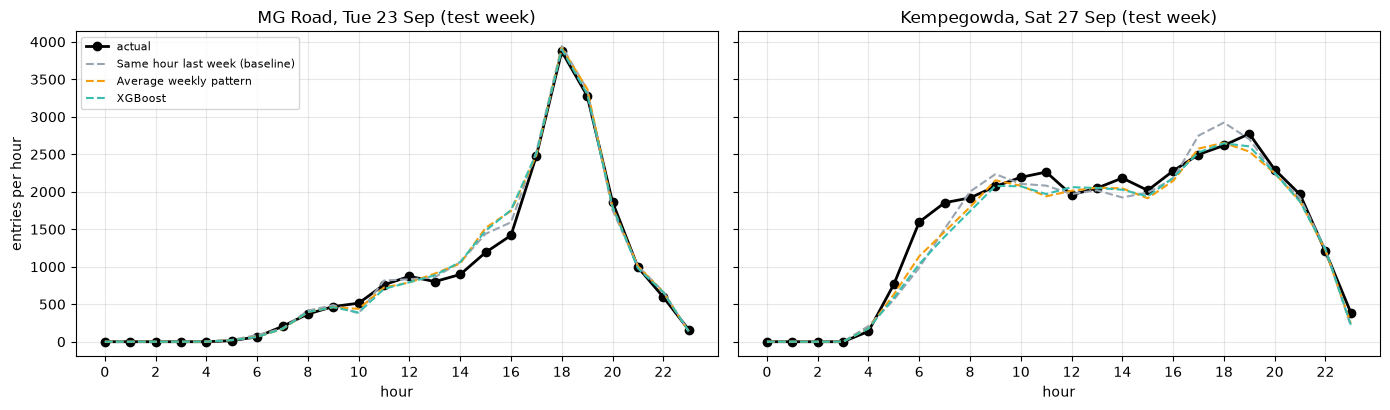

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
busiest = df.groupby("station")["entries"].sum().idxmax()
for ax, (station, day) in zip(axes, [("MG Road", "2025-09-23"), (busiest, "2025-09-27")]):
    g = test[(test["station"] == station) & (test["date"] == day)].sort_values("hour")
    if g.empty:
        ax.set_title(f"{station}: no data"); continue
    ax.plot(g["hour"], g["entries"], "o-", c="k", lw=2, label="actual")
    for col, c in [("pred_lastweek", "#9aa5b1"), ("pred_weekly", "#f59e0b"), ("pred_xgb", "#38bdae")]:
        ax.plot(g["hour"], g[col], "--", c=c, label=MODELS[col])
    ax.set(title=f"{station}, {pd.Timestamp(day):%a %d %b} (test week)", xlabel="hour", xticks=range(0, 24, 2))
    ax.grid(alpha=.3)
axes[0].set_ylabel("entries per hour"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Save the weekly pattern for the app

The best model by test MAE is refit on **all** data (1 Aug–30 Sep), using the same settings, and used to
predict every station × weekday × hour, assuming a normal (non-holiday) day. The app reads this small
table and shows the crowd curve and the least crowded hours.

In [8]:
best_col = results["MAE"].idxmin()
best_key = {v: k for k, v in MODELS.items()}[best_col]
print("Best model by test MAE:", best_col)

grid = pd.MultiIndex.from_product([sorted(df["station"].unique()), range(7), range(24)], names=["station", "weekday", "hour"]).to_frame(index=False)
grid["weekend"] = (grid["weekday"] >= 5).astype(int); grid["holiday"] = 0
if best_key == "pred_xgb":
    full = xgb.XGBRegressor(**final_params).fit(X(df), df["entries"])
    grid["expected_entries"] = np.clip(full.predict(X(grid)), 0, None)
else:
    normal_all = df[df["holiday"] == 0]
    grid = grid.merge(normal_all.groupby(["station", "weekday", "hour"])["entries"].mean().rename("expected_entries"),
                      on=["station", "weekday", "hour"], how="left").fillna({"expected_entries": 0})

grid["expected_entries"] = grid["expected_entries"].round(1)
out = grid[["station", "weekday", "hour", "expected_entries"]]
out.to_csv(os.path.join(APP_DATA, "metro_hourly_pattern.csv"), index=False)
print(f"Saved {len(out):,} rows ({out['station'].nunique()} stations x 7 days x 24 hours) to app/data/metro_hourly_pattern.csv")

ex = out[(out["station"] == "MG Road") & (out["weekday"] == 1) & (out["hour"].isin(OPEN_HOURS))].set_index("hour")["expected_entries"]
q = ex.nsmallest(2).index.sort_values(); b = ex.nlargest(2).index.sort_values()
print(f"\nExample, MG Road on a Tuesday: quietest {q[0]}:00 and {q[1]}:00 (~{ex[q].mean():.0f}/h), "
      f"busiest {b[0]}:00 and {b[1]}:00 (~{ex[b].mean():.0f}/h)")

Best model by test MAE: XGBoost


Saved 13,944 rows (83 stations x 7 days x 24 hours) to app/data/metro_hourly_pattern.csv

Example, MG Road on a Tuesday: quietest 6:00 and 7:00 (~119/h), busiest 18:00 and 19:00 (~3586/h)
